In [9]:
pip install --upgrade pip

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
    --------------------------------------- 0.0/2.0 MB 660.6 kB/s eta 0:00:03
   - -------------------------------------- 0.1/2.0 MB 825.8 kB/s eta 0:00:03
   -- ------------------------------------- 0.1/2.0 MB 1.2 MB/s eta 0:00:02
   ------ --------------------------------- 0.3/2.0 MB 1.8 MB/s eta 0:00:01
   ----------- ---------------------------- 0.6/2.0 MB 2.6 MB/s eta 0:00:01
   ---------------------- ----------------- 1.1/2.0 MB 4.4 MB/s eta 0:00:01
   ------------------------------ --------- 1.5/2.0 MB 5.0 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.9 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.0
    Uninstalling pip-24.0:
      Successfully uninstalled pip-24.0
Note: you may need to restart the kernel to use updated packages.


In [11]:
pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    "OrderID": [
        2001, 2002, 2003, 2004, 2005, 2006,
        2007, 2008, 2009, 2010, 2011, 2012
    ],

    "Date": [
        "2026-01-05", "2026-01-12", "2026-01-18",
        "2026-02-03", "2026-02-14", "2026-02-21",
        "2026-03-04", "2026-03-15", "2026-03-25",
        "2026-04-02", "2026-04-11", "2026-04-23"
    ],

    "Region": [
        "Mumbai", "Chennai", "Delhi", "Mumbai",
        "Bangalore", "Hyderabad", "Mumbai", "Chennai",
        "Delhi", "Bangalore", "Hyderabad", "Mumbai"
    ],

    "Product": [
        "MI Jersey", "MI Cap", "MI Jersey", "MI T-Shirt",
        "MI Flag", "MI Jersey", "MI Cap", "MI Jersey",
        "MI T-Shirt", "MI Jersey", "MI Cap", "MI Flag"
    ],

    "Units": [2, 4, 1, 3, 5, 2, 6, 1, 4, 2, 3, 5],

    "UnitPrice": [
        1499, 499, 1499, 899,
        199, 1499, 499, 1499,
        899, 1499, 499, 199
    ],

    "DiscountPct": [
        0.05, 0.00, 0.10, 0.10,
        0.00, 0.05, 0.00, 0.15,
        0.00, 0.10, 0.00, 0.05
    ],

    "Channel": [
        "Online", "Store", "Store", "Online",
        "Store", "Online", "Store", "Online",
        "Store", "Online", "Online", "Store"
    ]
}

df = pd.DataFrame(data)

df

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel
0,2001,2026-01-05,Mumbai,MI Jersey,2,1499,0.05,Online
1,2002,2026-01-12,Chennai,MI Cap,4,499,0.00,Store
2,2003,2026-01-18,Delhi,MI Jersey,1,1499,0.10,Store
3,2004,2026-02-03,Mumbai,MI T-Shirt,3,899,0.10,Online
4,2005,2026-02-14,Bangalore,MI Flag,5,199,0.00,Store
5,2006,2026-02-21,Hyderabad,MI Jersey,2,1499,0.05,Online
6,2007,2026-03-04,Mumbai,MI Cap,6,499,0.00,Store
7,2008,2026-03-15,Chennai,MI Jersey,1,1499,0.15,Online
8,2009,2026-03-25,Delhi,MI T-Shirt,4,899,0.00,Store
9,2010,2026-04-02,Bangalore,MI Jersey,2,1499,0.10,Online


In [13]:
# Check unique orders
df["OrderID"].nunique(), len(df)

# Convert Date column into datetime
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# Check missing dates
df["Date"].isna().sum()

# Check datatypes
df.dtypes

OrderID                 int64
Date           datetime64[us]
Region                    str
Product                   str
Units                   int64
UnitPrice               int64
DiscountPct           float64
Channel                   str
dtype: object

In [14]:
df["Revenue"] = (
    df["Units"]
    * df["UnitPrice"]
    * (1 - df["DiscountPct"])
)

df

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
0,2001,2026-01-05,Mumbai,MI Jersey,2,1499,0.05,Online,2848.10
1,2002,2026-01-12,Chennai,MI Cap,4,499,0.00,Store,1996.00
2,2003,2026-01-18,Delhi,MI Jersey,1,1499,0.10,Store,1349.10
3,2004,2026-02-03,Mumbai,MI T-Shirt,3,899,0.10,Online,2427.30
4,2005,2026-02-14,Bangalore,MI Flag,5,199,0.00,Store,995.00
5,2006,2026-02-21,Hyderabad,MI Jersey,2,1499,0.05,Online,2848.10
6,2007,2026-03-04,Mumbai,MI Cap,6,499,0.00,Store,2994.00
7,2008,2026-03-15,Chennai,MI Jersey,1,1499,0.15,Online,1274.15
8,2009,2026-03-25,Delhi,MI T-Shirt,4,899,0.00,Store,3596.00
9,2010,2026-04-02,Bangalore,MI Jersey,2,1499,0.10,Online,2698.20


In [15]:
highest_revenue_orders = (
    df.sort_values(
        "Revenue",
        ascending=False
    )
    [[
        "OrderID",
        "Date",
        "Region",
        "Product",
        "Units",
        "UnitPrice",
        "DiscountPct",
        "Revenue"
    ]]
    .head(5)
)

highest_revenue_orders

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
8,2009,2026-03-25,Delhi,MI T-Shirt,4,899,0.00,3596.0
6,2007,2026-03-04,Mumbai,MI Cap,6,499,0.00,2994.0
0,2001,2026-01-05,Mumbai,MI Jersey,2,1499,0.05,2848.1
5,2006,2026-02-21,Hyderabad,MI Jersey,2,1499,0.05,2848.1
9,2010,2026-04-02,Bangalore,MI Jersey,2,1499,0.10,2698.2


In [16]:
product_summary = (
    df.groupby("Product")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Units", "sum"),
        Orders=("OrderID", "count")
    )
    .sort_values(
        "TotalRevenue",
        ascending=False
    )
)

product_summary

,TotalRevenue,UnitsSold,Orders
Product,,,
MI Jersey,11017.65,8,5
MI Cap,6487.00,13,3
MI T-Shirt,6023.30,7,2
MI Flag,1940.25,10,2


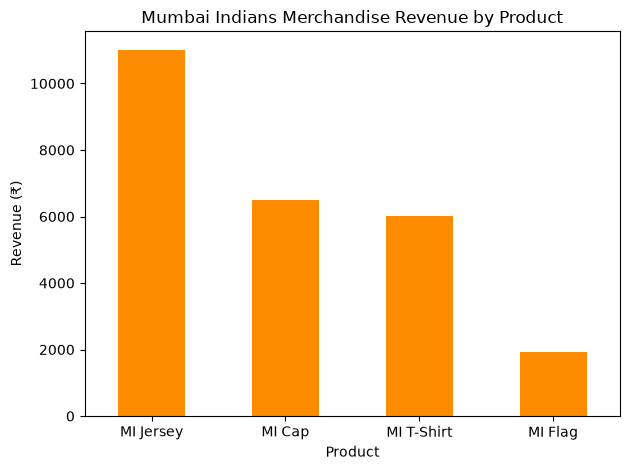

In [17]:
product_summary["TotalRevenue"].plot(
    kind="bar",
    color="darkorange",
    title="Mumbai Indians Merchandise Revenue by Product"
)

plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

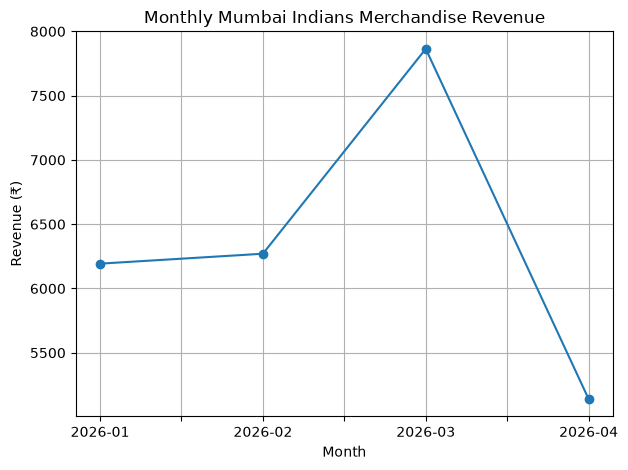

In [20]:
monthly_summary["TotalRevenue"].plot(
    kind="line",
    marker="o",
    title="Monthly Mumbai Indians Merchandise Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
df["Month"] = (
    df["Date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_summary = (
    df.groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "count"),
        UnitsSold=("Units", "sum")
    )
    .sort_index()
)

monthly_summary

,TotalRevenue,Orders,UnitsSold
Month,,,
2026-01,6193.20,3,7
2026-02,6270.40,3,10
2026-03,7864.15,3,11
2026-04,5140.45,3,10
